# 01 · Exploratory Data Analysis — GB Electricity Demand

**Question for this notebook:** what drives Great Britain's half-hourly electricity demand, and where does the industry's own day-ahead forecast (NESO) go wrong?

The answers decide which features the forecasting model needs (Phase 6–7) and where there is room to beat NESO.

**Data:** `fact_demand_hh` in `data/energy.duckdb` — one row per half-hour, 2019 → Oct 2026, built by `python -m src.data.build_database`.
Demand = **ND (national demand)**, in MW. Charts show **GW** (1 GW = 1,000 MW).

| Section | Question |
|---|---|
| 1 | Is GB demand falling? |
| 2 | Daily and weekly patterns |
| 3 | How much does temperature matter? |
| 4 | Rooftop solar hides demand |
| 5 | COVID-19: a natural experiment |
| 6 | Where does NESO's forecast go wrong? |
| 7 | Summary and implications for modelling |

In [1]:
import sys
from pathlib import Path

# Make the project's src/ package importable whether Jupyter starts in notebooks/ or the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.config import DB_PATH, FIGURES_DIR
from src.viz import AQUA, BLUE, MUTED, ORANGE, RED, SEQUENTIAL_BLUE, TEXT_2, YELLOW, save, set_style

set_style()
pd.set_option("display.float_format", "{:,.1f}".format)

con = duckdb.connect(str(DB_PATH), read_only=True)
df = con.sql("SELECT * FROM v_fact_enriched").df()
df["ts_local"] = pd.to_datetime(df["ts_local"])
df["gw"] = df["nd_mw"] / 1000
print(f"{len(df):,} half-hours  |  {df['settlement_date'].min():%Y-%m-%d} to {df['settlement_date'].max():%Y-%m-%d}")

136,558 half-hours  |  2019-01-01 00:00:00 to 2026-10-15 00:00:00


## 1 · Is GB demand falling?

`v_annual_summary` (SQL view, uses `LAG()` for year-on-year change). 2026 is a part year, so the chart compares **the same calendar window (1 Jan → 15 Oct) in every year**.

Two measures:
- **ND** — what the transmission grid sees.
- **Underlying demand** = ND + embedded solar + embedded wind — what people actually consume, including power from small generators connected to local networks that the grid never sees.

,year,days,avg_nd_mw,peak_nd_mw,avg_underlying_mw,solar_capacity_mw,embedded_solar_twh,nd_yoy_pct
0,2019,365.0,"29,358.0",47081,"32,442.0",13040,11.5,NaN
1,2020,366.0,"27,157.0",45986,"30,607.0",13471,12.1,-7.5
2,2021,365.0,"28,345.0",46433,"31,378.0",14008,11.7,4.4
3,2022,365.0,"26,622.0",46147,"30,023.0",15037,13.2,-6.1
4,2023,365.0,"26,052.0",44109,"29,364.0",16793,13.4,-2.1
5,2024,366.0,"26,287.0",45202,"29,807.0",18720,13.9,0.9
6,2025,365.0,"26,158.0",45924,"30,240.0",22126,18.7,-0.5
7,2026,288.0,"25,194.0",47382,"29,929.0",23963,19.6,-3.7


2019 -> 2026 (1 Jan to day 288):
  ND                 -11.6%
  Underlying demand  -5.7%
  Solar capacity     +85.3%  (12.9 -> 24.0 GW)


C:\Users\bogad\AppData\Local\Temp\ipykernel_27904\947899546.py:5: Pandas4Warning: Timestamp.dayofyear is deprecated and will be removed in a future version. Use Timestamp.day_of_year instead.
  last_doy = df["ts_local"].max().dayofyear
C:\Users\bogad\AppData\Local\Temp\ipykernel_27904\947899546.py:6: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ytd = (df[df["ts_local"].dt.dayofyear <= last_doy]


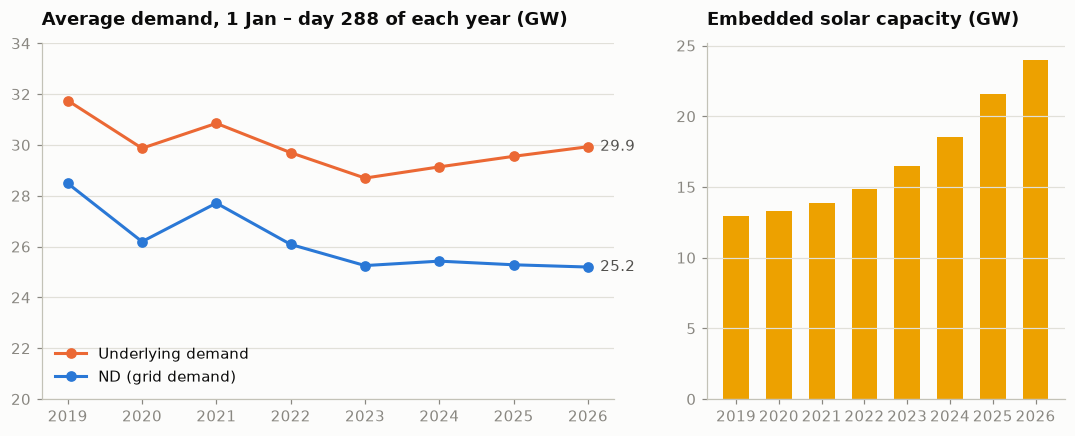

In [2]:
annual = con.sql("SELECT * FROM v_annual_summary").df()
display(annual)

# Like-for-like window: same days of the year as the latest (partial) year
last_doy = df["ts_local"].max().day_of_year
ytd = (df[df["ts_local"].dt.day_of_year <= last_doy]
       .groupby("year")[["nd_mw", "underlying_demand_mw", "embedded_solar_capacity_mw"]]
       .agg({"nd_mw": "mean", "underlying_demand_mw": "mean", "embedded_solar_capacity_mw": "max"}) / 1000)

first, last = ytd.index.min(), ytd.index.max()
chg = lambda col: 100 * (ytd.loc[last, col] / ytd.loc[first, col] - 1)
print(f"{first} -> {last} (1 Jan to day {last_doy}):")
print(f"  ND                 {chg('nd_mw'):+.1f}%")
print(f"  Underlying demand  {chg('underlying_demand_mw'):+.1f}%")
print(f"  Solar capacity     {chg('embedded_solar_capacity_mw'):+.1f}%  "
      f"({ytd.loc[first, 'embedded_solar_capacity_mw']:.1f} -> {ytd.loc[last, 'embedded_solar_capacity_mw']:.1f} GW)")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax1.plot(ytd.index, ytd["underlying_demand_mw"], marker="o", ms=6, color=ORANGE, label="Underlying demand")
ax1.plot(ytd.index, ytd["nd_mw"], marker="o", ms=6, color=BLUE, label="ND (grid demand)")
for col, color in [("underlying_demand_mw", ORANGE), ("nd_mw", BLUE)]:
    ax1.annotate(f"{ytd[col].iloc[-1]:.1f}", (last, ytd[col].iloc[-1]), xytext=(8, 0),
                 textcoords="offset points", va="center", color=TEXT_2)
ax1.set_title(f"Average demand, 1 Jan – day {last_doy} of each year (GW)")
ax1.set_ylim(20, 34)
ax1.legend(loc="lower left")
ax2.bar(ytd.index, ytd["embedded_solar_capacity_mw"], color=YELLOW, width=0.6)
ax2.set_title("Embedded solar capacity (GW)")
for ax in (ax1, ax2):
    ax.set_xticks(ytd.index)
save(fig, "01_demand_trend", FIGURES_DIR)
plt.show()

**Finding 1 — the grid sees falling demand, but consumption has fallen much less.**
Comparing the same window (1 Jan – 15 Oct) each year, **ND fell 11.6% from 2019 to 2026, but underlying demand fell only 5.7%.** Over the same period embedded solar capacity grew **85% (12.9 → 24.0 GW)**. Since 2023 underlying demand has started rising again (about +4%) while ND has stayed flat — the extra consumption is being met by local solar.

The gap between the two lines is mostly **rooftop and small-scale solar**: as capacity grows, more consumption is met behind the meter and disappears from ND. A model of ND therefore has to model solar, not just people.

## 2 · Daily and weekly patterns

Profiles use **2025** (the latest full year), working days only, in UK local time.

        peak_gw  peak_time
season                    
Winter     40.6       17.5
Spring     31.4       19.0
Summer     27.4       19.5
Autumn     33.8       18.0


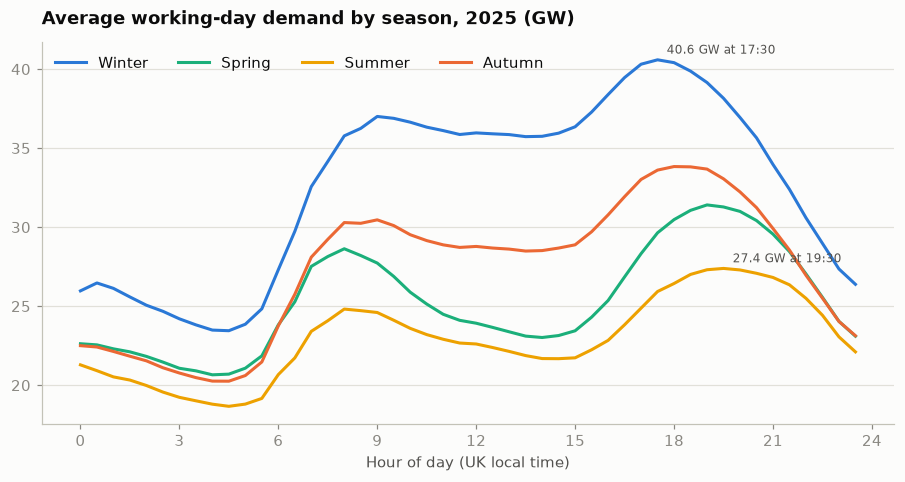

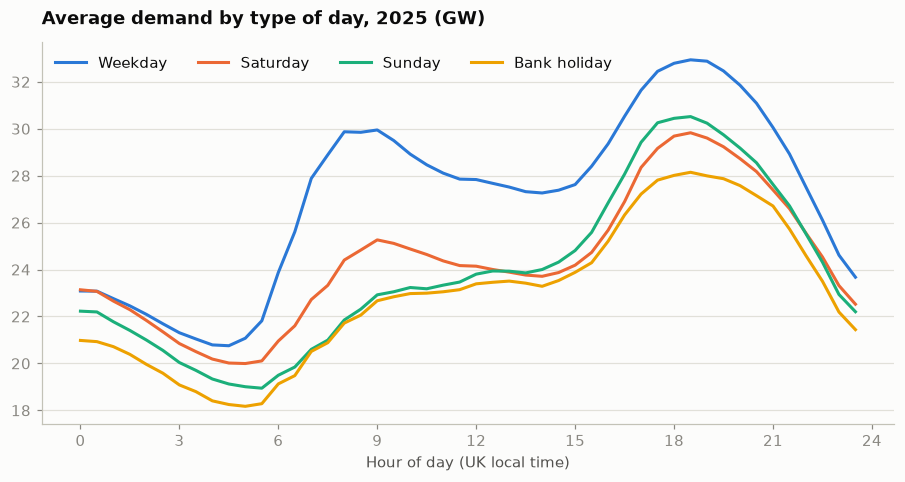

day_type
Bank holiday   -15.3
Saturday       -10.1
Sunday         -11.9
Weekday          0.0


In [3]:
d25 = df[(df["year"] == 2025)]
workdays = d25[~d25["is_weekend"] & ~d25["is_bank_holiday"]]
season_order = ["Winter", "Spring", "Summer", "Autumn"]
colors = dict(zip(season_order, [BLUE, AQUA, YELLOW, ORANGE]))

profile = workdays.groupby(["season", "hour_local"])["gw"].mean().unstack(0)[season_order]
fig, ax = plt.subplots()
for s in season_order:
    ax.plot(profile.index, profile[s], color=colors[s], label=s)
for s in ["Winter", "Summer"]:  # label only the extremes to avoid clutter
    peak_h = profile[s].idxmax()
    ax.annotate(f"{profile[s].max():.1f} GW at {int(peak_h):02d}:{int(peak_h % 1 * 60):02d}",
                (peak_h, profile[s].max()), xytext=(6, 4), textcoords="offset points", fontsize=8, color=TEXT_2)
ax.set_title("Average working-day demand by season, 2025 (GW)")
ax.set_xlabel("Hour of day (UK local time)")
ax.set_xticks(range(0, 25, 3))
ax.legend(ncol=4, loc="upper left")
peaks_by_season = pd.DataFrame({"peak_gw": profile.max(), "peak_time": profile.idxmax()})
print(peaks_by_season.round(1).to_string())
save(fig, "02_daily_profile_by_season", FIGURES_DIR)
plt.show()

def day_type(r):
    if r["is_bank_holiday"]: return "Bank holiday"
    return {6: "Saturday", 7: "Sunday"}.get(r["day_of_week"], "Weekday")

d25 = d25.assign(day_type=d25.apply(day_type, axis=1))
by_type = d25.groupby(["day_type", "hour_local"])["gw"].mean().unstack(0)
order = ["Weekday", "Saturday", "Sunday", "Bank holiday"]
fig, ax = plt.subplots()
for name, color in zip(order, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.plot(by_type.index, by_type[name], color=color, label=name)
ax.set_title("Average demand by type of day, 2025 (GW)")
ax.set_xlabel("Hour of day (UK local time)")
ax.set_xticks(range(0, 25, 3))
ax.legend(ncol=4, loc="upper left")
save(fig, "03_profile_by_day_type", FIGURES_DIR)
plt.show()

means = d25.groupby("day_type")["gw"].mean()
print((100 * (means / means["Weekday"] - 1)).round(1).rename("% vs weekday").to_string())

**Finding 2 — strong, regular cycles.**
- Working-day **winter peak ≈ 40.6 GW at 17:30**; summer peak ≈ 27.4 GW, later (19:30) and a third lower.
- A steep **morning ramp 06:00–09:00**, an overnight trough around 04:30.
- Compared with weekdays, average demand is **10% lower on Saturdays, 12% lower on Sundays and 15% lower on bank holidays** — bank holidays behave like a quiet Sunday.

These cycles are why simple baselines ("same time last week") are already fairly accurate — and why the model needs calendar features: time of day, day of week, bank holidays.

## 3 · How much does temperature matter?

Daily average demand against **population-weighted** daily temperature (6 cities), working days from 2023 on (to keep the long-term trend out of the picture).

Below 15 °C: -842 MW per +1 °C   |   above 18 °C: +219 MW per +1 °C  (135 days)


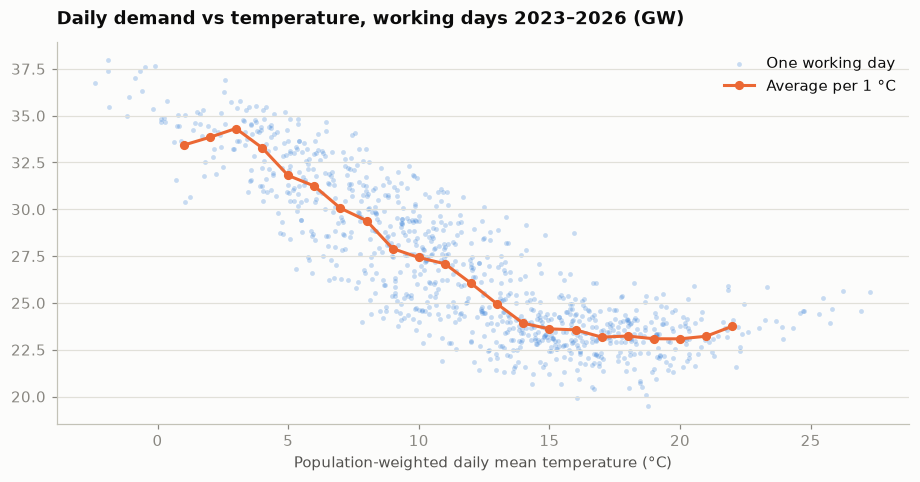

In [4]:
daily = (df[~df["is_weekend"] & ~df["is_bank_holiday"] & (df["year"] >= 2023)]
         .groupby("settlement_date")
         .agg(gw=("gw", "mean"), temp=("wa_temperature", "mean")))
bins = daily.groupby(daily["temp"].round())["gw"].agg(["mean", "size"])
bins = bins[bins["size"] >= 10]

cold = daily[daily["temp"] < 15]
slope_cold = np.polyfit(cold["temp"], cold["gw"] * 1000, 1)[0]
warm = daily[daily["temp"] > 18]
slope_warm = np.polyfit(warm["temp"], warm["gw"] * 1000, 1)[0] if len(warm) > 20 else np.nan
print(f"Below 15 °C: {slope_cold:,.0f} MW per +1 °C   |   above 18 °C: {slope_warm:+,.0f} MW per +1 °C  ({len(warm)} days)")

fig, ax = plt.subplots()
ax.scatter(daily["temp"], daily["gw"], s=10, color=BLUE, alpha=0.25, linewidths=0, label="One working day")
ax.plot(bins.index, bins["mean"], color=ORANGE, marker="o", ms=5, label="Average per 1 °C")
ax.set_title("Daily demand vs temperature, working days 2023–2026 (GW)")
ax.set_xlabel("Population-weighted daily mean temperature (°C)")
ax.legend(loc="upper right")
save(fig, "04_temperature_vs_demand", FIGURES_DIR)
plt.show()

**Finding 3 — cold drives demand; heat barely does (yet).**
- Below ~15 °C, **every 1 °C colder adds about 840 MW** (~3% of average demand) — electric heating and lighting.
- Between 15 and 22 °C demand is flat.
- Above 18 °C there is a small upward slope (~+220 MW per °C, 135 days) — an early cooling (air-conditioning) signal, still minor in GB.

The relationship is **not a straight line**, which favours tree-based models (gradient boosting) or explicit "heating degree" features over plain linear regression.

## 4 · Rooftop solar hides demand

Summer working days (May–Aug, 2025–26) at midday (12:00–14:00). Each point groups half-hours by how much embedded solar was generating.

Each extra 1 GW of embedded solar lowers midday ND by ~0.68 GW


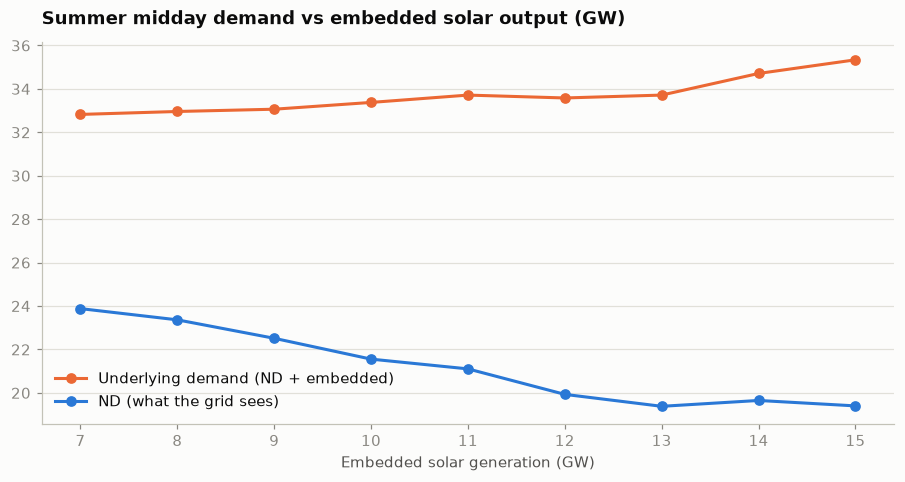

In [5]:
mid = df[df["month"].between(5, 8) & (df["year"] >= 2025) & df["hour_local"].between(12, 13.5)
         & ~df["is_weekend"] & ~df["is_bank_holiday"]].copy()
mid["solar_bin"] = (mid["embedded_solar_mw"] / 1000).round()
s = mid.groupby("solar_bin")[["nd_mw", "underlying_demand_mw"]].mean().div(1000)
s = s[mid.groupby("solar_bin").size() >= 30]

slope = np.polyfit(mid["embedded_solar_mw"], mid["nd_mw"], 1)[0]
print(f"Each extra 1 GW of embedded solar lowers midday ND by ~{-slope:.2f} GW")

fig, ax = plt.subplots()
ax.plot(s.index, s["underlying_demand_mw"], marker="o", ms=6, color=ORANGE, label="Underlying demand (ND + embedded)")
ax.plot(s.index, s["nd_mw"], marker="o", ms=6, color=BLUE, label="ND (what the grid sees)")
ax.set_title("Summer midday demand vs embedded solar output (GW)")
ax.set_xlabel("Embedded solar generation (GW)")
ax.legend(loc="lower left")
save(fig, "05_solar_hides_demand", FIGURES_DIR)
plt.show()

**Finding 4 — on sunny days, demand "disappears" from the grid almost one-for-one.**
At summer middays, **every extra 1 GW of embedded solar lowers ND by about 0.7 GW**. Across the range ND falls by ~4.5 GW, while underlying demand stays roughly flat and even rises slightly (sunny days are warmer, and NESO's embedded-solar figures are themselves estimates, not meter readings).

Consumption (orange) stays roughly flat while ND (blue) falls. So **forecasting ND at midday is mostly forecasting the sun**: solar radiation forecasts × installed solar capacity must be a model feature.

## 5 · COVID-19: a natural experiment

7-day rolling average of daily demand, 2019 vs 2020, aligned by day of year. The first national lockdown began on **23 March 2020**.

23 Mar – 10 May: 2020 demand -18.0% vs the same dates in 2019


C:\Users\bogad\AppData\Local\Temp\ipykernel_27904\85901220.py:2: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  d["doy"] = pd.to_datetime(d["settlement_date"]).dt.dayofyear


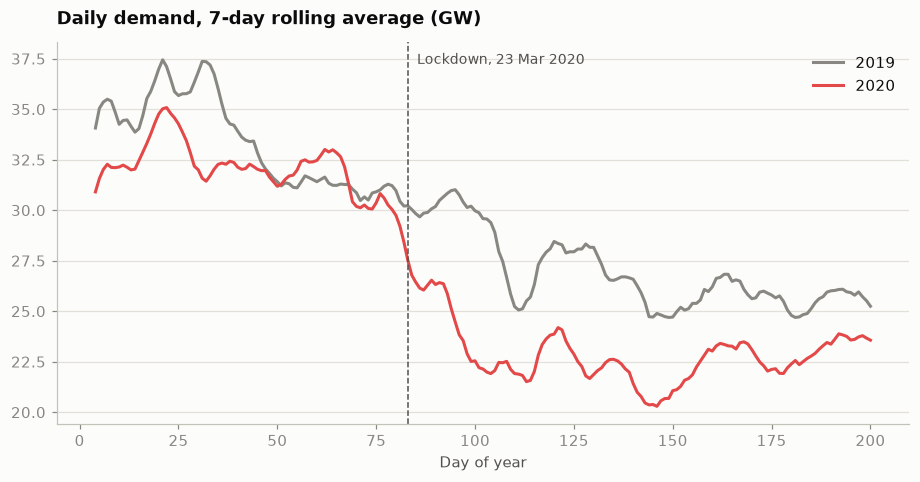

In [6]:
d = df.groupby("settlement_date").agg(gw=("gw", "mean"), year=("year", "first")).reset_index()
d["doy"] = pd.to_datetime(d["settlement_date"]).dt.day_of_year
d["roll7"] = d.groupby("year")["gw"].transform(lambda x: x.rolling(7, center=True).mean())

lock = lambda y: (pd.to_datetime(d["settlement_date"]) >= f"{y}-03-23") & (pd.to_datetime(d["settlement_date"]) < f"{y}-05-11")
drop = 100 * (d.loc[lock(2020) & (d["year"] == 2020), "gw"].mean() /
              d.loc[lock(2019) & (d["year"] == 2019), "gw"].mean() - 1)
print(f"23 Mar – 10 May: 2020 demand {drop:+.1f}% vs the same dates in 2019")

fig, ax = plt.subplots()
for y, color in [(2019, MUTED), (2020, RED)]:
    x = d[(d["year"] == y) & (d["doy"] <= 200)]
    ax.plot(x["doy"], x["roll7"], color=color, label=str(y))
ax.axvline(83, color=TEXT_2, lw=1, ls="--")
ax.annotate("Lockdown, 23 Mar 2020", (83, ax.get_ylim()[1]), xytext=(6, -14), textcoords="offset points", color=TEXT_2, fontsize=9)
ax.set_title("Daily demand, 7-day rolling average (GW)")
ax.set_xlabel("Day of year")
ax.legend(loc="upper right")
save(fig, "06_covid_lockdown", FIGURES_DIR)
plt.show()

**Finding 5 — lockdown removed about a sixth of demand overnight.**
Between 23 March and 10 May 2020, demand was **18% lower** than on the same dates in 2019 — offices, shops and factories closed, and more people at home did not make up for it.

2020 is a structural break: a model trained on it learns behaviour that no longer exists. Option for Phase 6: train from 2021, or keep 2020 with a "lockdown" flag. We will test both.

## 6 · Where does NESO's forecast go wrong?

NESO's day-ahead forecast vs actual ND (Apr 2021 → Oct 2026). Autumn clock-change days are excluded (see README). Error = forecast − actual, so **positive = NESO over-forecast**.

,mae_mw,mape_pct,bias_mw
year,,,
2021,579.5,2.1,-21.9
2022,621.3,2.3,-9.6
2023,596.2,2.3,-13.3
2024,620.6,2.4,-27.2
2025,678.6,2.7,14.5
2026,778.9,3.2,-49.5


MAPE at each day's peak half-hour: {2021: 1.86, 2022: 2.01, 2023: 1.9, 2024: 1.89, 2025: 2.04, 2026: 2.51}


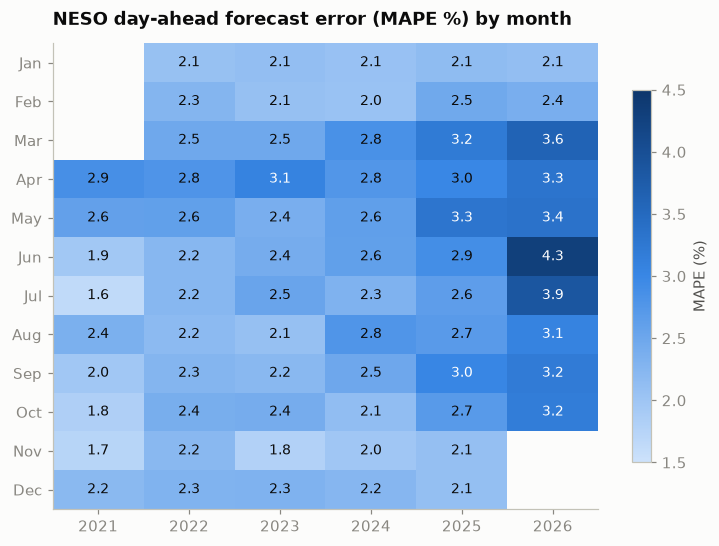

In [7]:
neso = con.sql("SELECT * FROM v_neso_error_monthly").df()
yearly = (df.dropna(subset=["neso_forecast_mw"])
          .assign(ae=lambda x: x["neso_error_mw"].abs(), ape=lambda x: 100 * x["neso_error_mw"].abs() / x["nd_mw"])
          .groupby("year").agg(mae_mw=("ae", "mean"), mape_pct=("ape", "mean"), bias_mw=("neso_error_mw", "mean")))
display(yearly)

peaks = con.sql("SELECT * FROM v_daily_peaks WHERE neso_peak_error_mw IS NOT NULL").df()
peaks["year"] = pd.to_datetime(peaks["settlement_date"]).dt.year
peaks["ape"] = 100 * peaks["neso_peak_error_mw"].abs() / peaks["peak_nd_mw"]
print("MAPE at each day's peak half-hour:", peaks.groupby("year")["ape"].mean().round(2).to_dict())

# Heatmap: MAPE by month and year
grid = neso.pivot(index="month", columns="year", values="mape_pct")
fig, ax = plt.subplots(figsize=(8, 5.5))
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("seq_blue", SEQUENTIAL_BLUE)
im = ax.imshow(grid.values, cmap=cmap, aspect="auto", vmin=1.5, vmax=4.5)
ax.set_xticks(range(len(grid.columns)), grid.columns)
ax.set_yticks(range(12), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.grid(False)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 3.0 else "#0b0b0b")
fig.colorbar(im, ax=ax, label="MAPE (%)", shrink=0.8)
ax.set_title("NESO day-ahead forecast error (MAPE %) by month")
save(fig, "07_neso_error_heatmap", FIGURES_DIR)
plt.show()

Midday (11:00–14:59) MAE: 855 MW in 2022 -> 1,083 MW in 2025
Night  (00:00–04:59) MAE: 387 MW in 2022 -> 404 MW in 2025


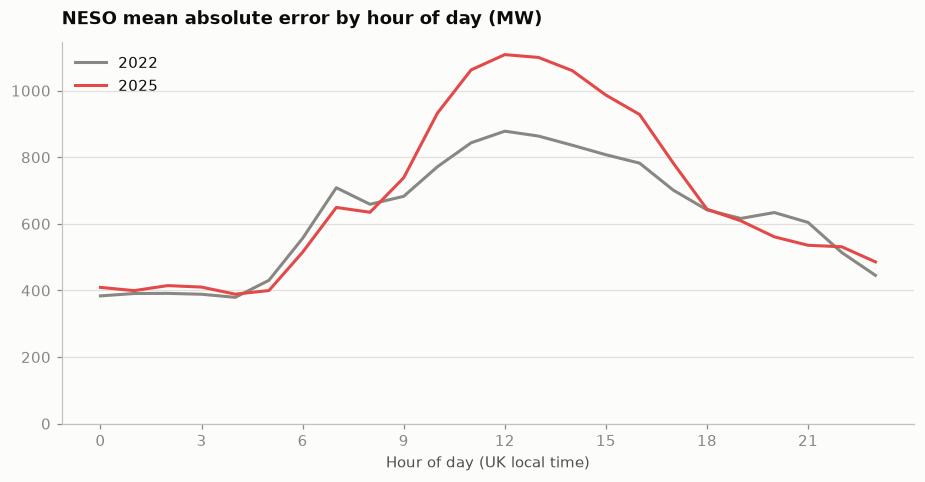

                    bias  solar
solar_q                        
(273.999, 3854.0] -528.2    2.8
(3854.0, 5222.0]  -242.3    4.6
(5222.0, 6637.0]    29.3    5.9
(6637.0, 8517.0]   321.7    7.5
(8517.0, 16393.0]  666.5   10.6


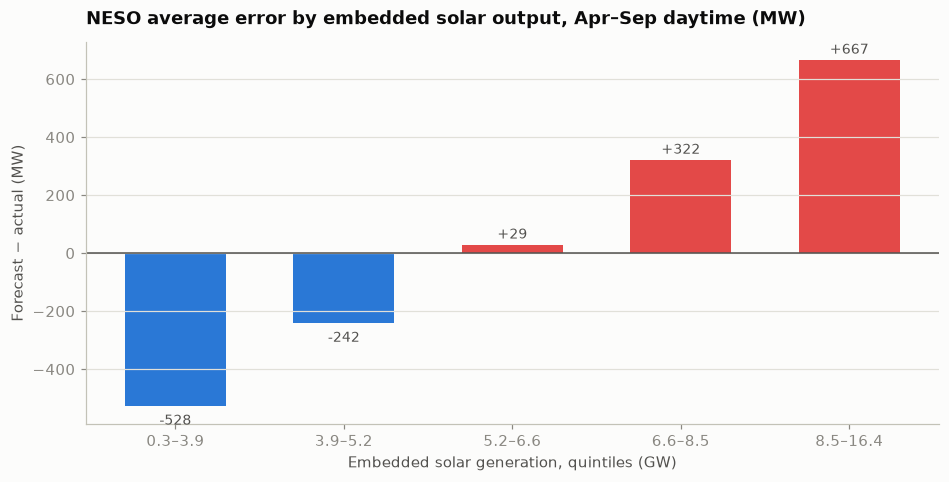

In [8]:
n = df.dropna(subset=["neso_forecast_mw"]).copy()
n["ae"] = n["neso_error_mw"].abs()
n["hour"] = n["hour_local"].astype(int)
y0, y1 = 2022, 2025
by_hour = n[n["year"].isin([y0, y1])].pivot_table(index="hour", columns="year", values="ae", aggfunc="mean")
print(f"Midday (11:00–14:59) MAE: {by_hour.loc[11:14, y0].mean():,.0f} MW in {y0} -> {by_hour.loc[11:14, y1].mean():,.0f} MW in {y1}")
print(f"Night  (00:00–04:59) MAE: {by_hour.loc[0:4, y0].mean():,.0f} MW in {y0} -> {by_hour.loc[0:4, y1].mean():,.0f} MW in {y1}")

fig, ax = plt.subplots()
ax.plot(by_hour.index, by_hour[y0], color=MUTED, label=str(y0))
ax.plot(by_hour.index, by_hour[y1], color=RED, label=str(y1))
ax.set_title("NESO mean absolute error by hour of day (MW)")
ax.set_xlabel("Hour of day (UK local time)")
ax.set_xticks(range(0, 24, 3))
ax.set_ylim(0, None)
ax.legend(loc="upper left")
save(fig, "08_neso_error_by_hour", FIGURES_DIR)
plt.show()

# Bias vs solar: daytime, April–September
day = n[n["month"].between(4, 9) & n["hour_local"].between(9, 17)].copy()
day["solar_q"] = pd.qcut(day["embedded_solar_mw"], 5)
b = day.groupby("solar_q", observed=True).agg(bias=("neso_error_mw", "mean"), solar=("embedded_solar_mw", "mean"))
labels = [f"{iv.left/1000:.1f}–{iv.right/1000:.1f}" for iv in b.index]
print(b.assign(solar=lambda x: x["solar"] / 1000).round(1).to_string())

fig, ax = plt.subplots()
ax.bar(labels, b["bias"], color=[BLUE if v < 0 else RED for v in b["bias"]], width=0.6)
ax.axhline(0, color=TEXT_2, lw=1)
for i, v in enumerate(b["bias"]):
    ax.annotate(f"{v:+,.0f}", (i, v), xytext=(0, 4 if v >= 0 else -12), textcoords="offset points",
                ha="center", fontsize=9, color=TEXT_2)
ax.set_title("NESO average error by embedded solar output, Apr–Sep daytime (MW)")
ax.set_xlabel("Embedded solar generation, quintiles (GW)")
ax.set_ylabel("Forecast − actual (MW)")
save(fig, "09_neso_bias_vs_solar", FIGURES_DIR)
plt.show()

**Finding 6 — NESO's forecast is getting worse, and the deterioration is a solar problem.**
- Average error rose from **2.1% (2021) to 3.2% (2026)** — MAE 580 → 780 MW. (2026 is Jan–Oct only, so it misses the low-error winter months, but the month-by-month heatmap shows the rise is real.)
- **Winter accuracy has not changed** (January ≈ 2.1% every year). The deterioration is all in **spring and summer**: June went from 1.9% (2021) to 4.3% (2026).
- **By hour:** night-time error is unchanged (~390 → 400 MW, 2022 → 2025), but **midday error rose 27% (855 → 1,083 MW)**.
- **The error flips sign with solar output.** On dull days NESO under-forecasts demand by ~530 MW; on the sunniest days it over-forecasts by ~670 MW. In other words, NESO's forecast does not capture the full day-to-day swing in solar: it expects too little solar on sunny days and too much on dull ones.
- Daily **evening peaks stay accurate** (~1.9–2.5%) because the sun has set.

**This is the opportunity:** a model that forecasts solar well (radiation forecast × installed capacity) has a realistic chance of beating NESO at sunny spring and summer middays — and probably not at winter evening peaks.

## 7 · Summary and implications for modelling

| # | Finding | What the model needs |
|---|---|---|
| 1 | ND falling (−11.6% since 2019) while solar capacity nearly doubled | Train on recent years; solar capacity as a feature |
| 2 | Strong daily, weekly and holiday cycles | Hour, day of week, bank holiday flags; lagged demand (same half-hour yesterday / last week) |
| 3 | Cold adds ~840 MW per °C, but the relationship is curved | Heating-degree features; a non-linear model (gradient boosting) |
| 4 | Each 1 GW of embedded solar removes ~0.7 GW of midday ND | Forecast solar radiation × installed capacity |
| 5 | 2020 lockdown: −18% | Exclude 2020 from training, or flag it |
| 6 | NESO's error has grown at sunny middays, not at evening peaks | Focus the comparison on spring/summer middays; report results by hour and season |

**Fair-test reminder:** when comparing with NESO (Phase 8) the model may only use *forecast* weather (`wf_*` columns, from March 2024), never actual weather.

**Caveats.** Embedded solar and wind in the NESO file are *estimates*, not metered output. Population weights are approximate. Findings are correlations from observational data — the solar link is strongly suggested by the timing (midday, spring/summer) and the sign flip in bias, but not proven causally.

In [9]:
con.close()
print("Figures saved to", FIGURES_DIR)

Figures saved to C:\Users\bogad\Documents\uk-energy-intelligence\reports\figures
